In [4]:
!pip install requests pandas geopandas matplotlib shapely

In [5]:
from google.colab import files
uploaded = files.upload()

Saving District.cpg to District.cpg
Saving District.dbf to District.dbf
Saving District.prj to District.prj
Saving District.sbn to District.sbn
Saving District.shp to District.shp
Saving District.shx to District.shx


In [6]:
import geopandas as gpd

nepal = gpd.read_file("District.shp")
nepal = nepal.to_crs("EPSG:4326")

In [7]:
import requests
import pandas as pd

url = "https://eonet.gsfc.nasa.gov/api/v3/events?limit=500&days=60"
data = requests.get(url).json()

records = []

for event in data['events']:
    category = event['categories'][0]['title']
    title = event['title']

    for geo in event['geometry']:
        if geo['type'] == 'Point':
            lon, lat = geo['coordinates']
            date = geo['date']

            records.append([title, category, date, lat, lon])

df = pd.DataFrame(records, columns=['title','category','date','lat','lon'])

In [8]:
relevant = ['Floods', 'Landslides']

df = df[df['category'].isin(relevant)]
df.head()

,title,category,date,lat,lon


In [9]:
from shapely.geometry import Point

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.lon, df.lat),
    crs="EPSG:4326"
)

In [10]:
gdf_nepal = gpd.sjoin(gdf, nepal, predicate="within")

No 'Floods' or 'Landslides' events were found in Nepal for the last 60 days.


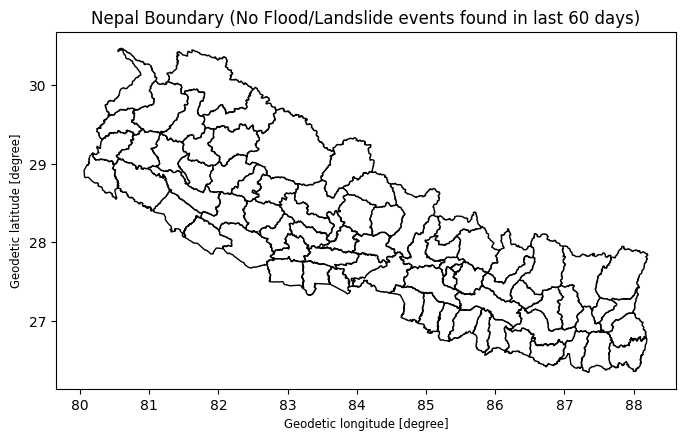

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,8))

nepal.plot(ax=ax, color="white", edgecolor="black")

# Check if gdf_nepal is empty before plotting
if not gdf_nepal.empty:
    gdf_nepal.plot(ax=ax, markersize=50)
    plt.title("Flood and Landslide Events in Nepal")
else:
    plt.title("Nepal Boundary (No Flood/Landslide events found in last 60 days)")
    print("No 'Floods' or 'Landslides' events were found in Nepal for the last 60 days.")

plt.show()

In [12]:
gdf_nepal['category'].value_counts()

,count
category,


In [13]:
gdf_nepal['date'] = pd.to_datetime(gdf_nepal['date'])

if not gdf_nepal.empty:
    gdf_nepal.set_index('date').resample('M').size().plot()
    plt.title("Monthly Flood and Landslide Events")
    plt.show()
else:
    print("No data to plot for monthly flood and landslide events.")

No data to plot for monthly flood and landslide events.


In [14]:
url = "https://eonet.gsfc.nasa.gov/api/v3/events?limit=1000&days=365"

In [15]:
df['category'].value_counts()

,count
category,


In [16]:
df_nepal = df[
    (df['lat'] > 26) & (df['lat'] < 31) &
    (df['lon'] > 80) & (df['lon'] < 89)
]

In [17]:
relevant = ['Severe Storms', 'Floods', 'Landslides']
df = df[df['category'].isin(relevant)]

No 'Floods' or 'Landslides' events were found in Nepal for the last 60 days.


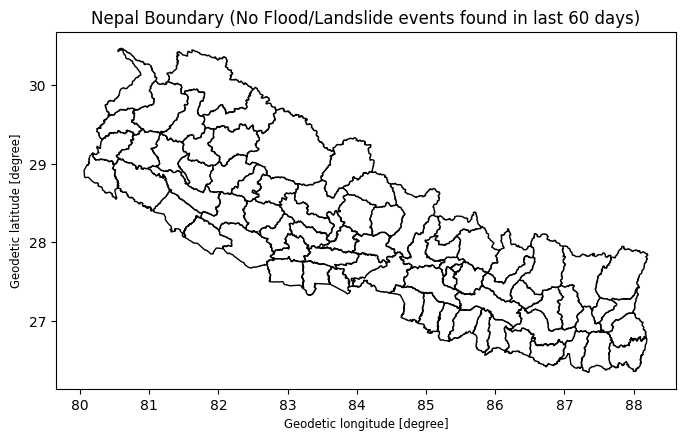

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,8))

nepal.plot(ax=ax, color="white", edgecolor="black")

# Check if gdf_nepal is empty before plotting
if not gdf_nepal.empty:
    gdf_nepal.plot(ax=ax, markersize=50)
    plt.title("Flood and Landslide Events in Nepal")
else:
    plt.title("Nepal Boundary (No Flood/Landslide events found in last 60 days)")
    print("No 'Floods' or 'Landslides' events were found in Nepal for the last 60 days.")

plt.show()

In [19]:
import requests
import pandas as pd

url = "https://earthquake.usgs.gov/fdsnws/event/1/query?format=geojson&starttime=2015-04-01&endtime=2015-06-30&minmagnitude=4"

data = requests.get(url).json()

records = []

for feature in data['features']:
    props = feature['properties']
    coords = feature['geometry']['coordinates']

    records.append([
        props['time'],
        props['mag'],
        props['place'],
        coords[1],  # lat
        coords[0]   # lon
    ])

df = pd.DataFrame(records, columns=['time','mag','place','lat','lon'])

In [20]:
df['time'] = pd.to_datetime(df['time'], unit='ms')

In [21]:
from shapely.geometry import Point

gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df.lon, df.lat),
    crs="EPSG:4326"
)

In [22]:
gdf_nepal = gpd.sjoin(gdf, nepal, predicate="within")

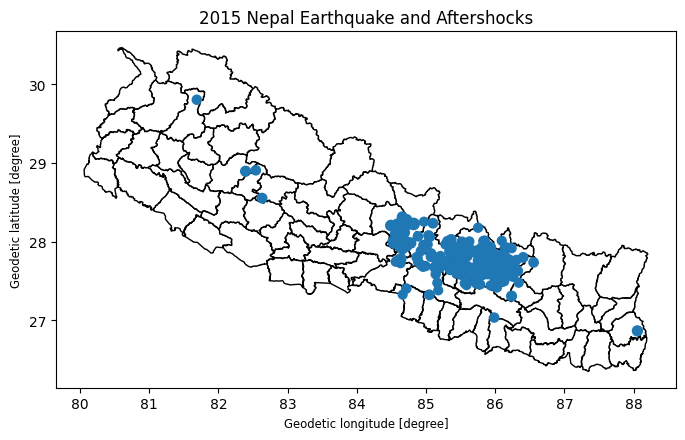

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,8))

nepal.plot(ax=ax, color="white", edgecolor="black")

gdf_nepal.plot(
    ax=ax,
    markersize=gdf_nepal['mag'] * 10
)

plt.title("2015 Nepal Earthquake and Aftershocks")
plt.show()

In [24]:
gdf_nepal['mag'].describe()

,mag
count,259.000000
mean,4.488649
std,0.511777
min,4.000000
25%,4.200000
50%,4.400000
75%,4.700000
max,7.800000


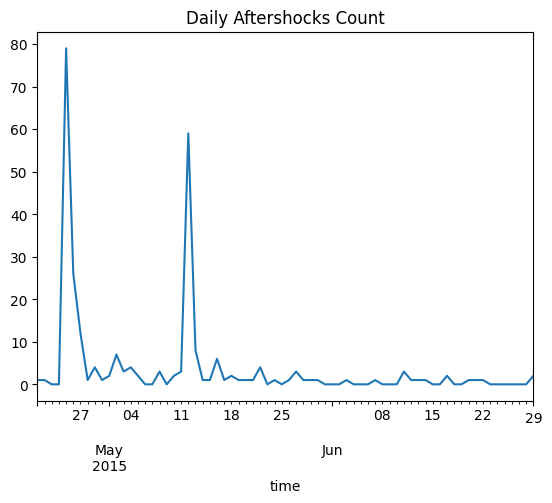

In [25]:
gdf_nepal.set_index('time').resample('D').size().plot()
plt.title("Daily Aftershocks Count")
plt.show()

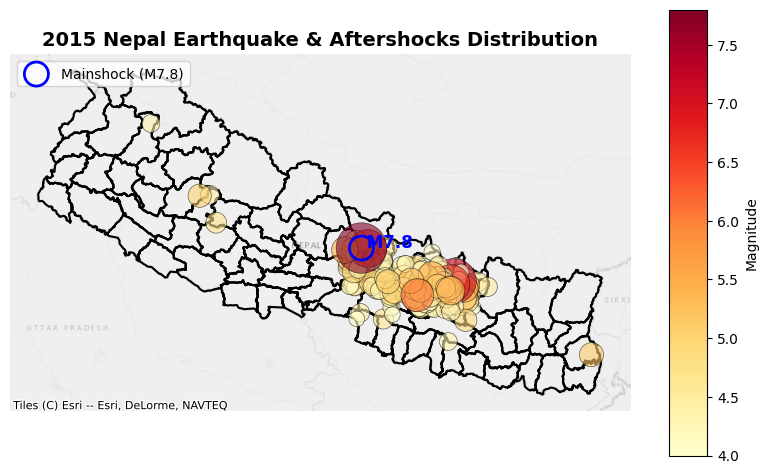

In [28]:
# To resolve the NameError:
# Please make sure to re-run the previous cells in the notebook first
# (specifically cell _cmAOwcjq3T- for 'nepal' and cell DP_EKVhusSPS for 'gdf_nepal')

!pip install contextily xyzservices

import sys
import matplotlib.pyplot as plt
import contextily as ctx

# Safely check if variables are loaded in the current namespace
if 'nepal' not in globals() or 'gdf_nepal' not in globals():
    print("ERROR: The variables 'nepal' and 'gdf_nepal' are not defined.")
    print("Please run all previous cells in the notebook first to import and prepare the geospatial data!")
else:
    # Project to Web Mercator (EPSG:3857) for proper contextily mapping
    nepal_3857 = nepal.to_crs(epsg=3857)
    gdf_nepal_3857 = gdf_nepal.to_crs(epsg=3857)

    fig, ax = plt.subplots(figsize=(10, 10))

    # Nepal boundary
    nepal_3857.plot(ax=ax, edgecolor='black', facecolor='none', linewidth=1.5, zorder=2)

    # Earthquakes in Nepal
    gdf_nepal_3857.plot(
        ax=ax,
        column='mag',
        cmap='YlOrRd',
        markersize=gdf_nepal_3857['mag']**3.5,
        legend=True,
        legend_kwds={'label': "Magnitude"},
        alpha=0.6,
        edgecolors='black',
        linewidths=0.5,
        zorder=3
    )

    # Find the mainshock within Nepal boundaries
    if not gdf_nepal_3857.empty:
        mainshock = gdf_nepal_3857.loc[gdf_nepal_3857['mag'].idxmax()]

        # Mainshock highlight
        ax.scatter(
            mainshock.geometry.x,
            mainshock.geometry.y,
            s=300,
            edgecolor='blue',
            facecolor='none',
            linewidth=2,
            label=f'Mainshock (M{mainshock["mag"]})',
            zorder=4
        )

        # Label
        ax.text(
            mainshock.geometry.x,
            mainshock.geometry.y,
            f" M{mainshock['mag']}",
            fontsize=12,
            fontweight='bold',
            color='blue',
            zorder=5
        )

    # Basemap: Using Esri.WorldGrayCanvas as a clean and reliable alternative with no API key required
    ctx.add_basemap(ax, source=ctx.providers.Esri.WorldGrayCanvas, zorder=1)

    # Layout
    ax.set_title("2015 Nepal Earthquake & Aftershocks Distribution", fontsize=14, fontweight='bold')
    ax.legend(loc='upper left')
    ax.set_axis_off()

    plt.show()